# Learning Activity 1: Data Understanding and Exploration (Actividad 1: Entendimiento y Exploración de Datos)
**Business Case:** North Quay Gifts | **Dataset:** Online Retail II (`online_retail_II.csv`)  
**CRISP-DM Phase:** Phase 2 — Data Understanding  
**Team Members:**
- Russel Emmanuel Ku Aguilar (ID: 2309131)
- Damian Nicolas Sanchez Novelo (ID: 2109134)
- Jonathan Abisai Velasco Martín (ID: 2309060)
- Ángel Rivaldo Canché Chuc (ID: 2309030)
- Bianca Alexandra Acosta Castellanos (ID: 2309001)

**Academic Advisor / Professor:** Didier Omar Gamboa Angulo (`didier.gamboa@upy.edu.mx`)  
**Institution:** Faculty of Data Engineering, Universidad Politécnica de Yucatán (UPY)

---
### Scope and Methodological Boundaries
This Jupyter notebook serves as the fully executed computational backbone for CRISP-DM Phase 2. Following strict project governance:
- **No records are prematurely deleted, imputed, or altered** in the base dataset.
- **No synthetic derived variables** (such as `LineAmount`) or aggregations are computed to replace atomic ledger lines.
- Temporary analytical filters and masks are used exclusively for case inspection.
- All 14 specific analytical questions and diagnostic tables are answered with verifiable empirical evidence directly backing the report.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings
warnings.filterwarnings('ignore')

# Academic styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Helvetica', 'Arial', 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#333333'
plt.rcParams['axes.linewidth'] = 0.8
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.4f' % x)

os.makedirs("figures", exist_ok=True)
print("Analysis environment successfully initialized.")

Analysis environment successfully initialized.


---
## 1. Data Recognition (Reconocimiento de los Datos)
Examination of dimensions, storage types, temporal coverage, and analytical semantics across all attributes.

In [2]:
# Load complete dataset
data_path = "../Data/online_retail_II.csv" if os.path.exists("../Data/online_retail_II.csv") else "Data/online_retail_II.csv"
df = pd.read_csv(data_path, encoding='utf-8')

n_rows, n_cols = df.shape
print(f"Dataset Dimensions: {n_rows:,} rows × {n_cols} columns")
df.head(3)

Dataset Dimensions: 1,067,371 rows × 8 columns


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.9500,13085.0000,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.7500,13085.0000,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.7500,13085.0000,United Kingdom


In [3]:
# Parse temporal range and assess cardinalities
df['InvoiceDateParsed'] = pd.to_datetime(df['InvoiceDate'])
min_datetime = df['InvoiceDateParsed'].min()
max_datetime = df['InvoiceDateParsed'].max()

distinct_invoices = df['Invoice'].nunique()
distinct_identified_customers = df['Customer ID'].dropna().nunique()

recognition_summary = pd.DataFrame({
    'Indicador': [
        'Número de líneas y columnas',
        'Primera y última fecha con hora',
        'Facturas distintas (Invoice)',
        'Clientes identificados distintos (Customer ID)',
        'Unidad representada por una fila'
    ],
    'Resultado': [
        f"{n_rows:,} filas × {n_cols} columnas",
        f"{min_datetime} a {max_datetime}",
        f"{distinct_invoices:,} facturas distintas",
        f"{distinct_identified_customers:,} clientes identificados (excluye nulos)",
        "Línea individual de ítem/producto dentro de una factura comercial"
    ]
})
recognition_summary

,Indicador,Resultado
0,Número de líneas y columnas,"1,067,371 filas × 8 columnas"
1,Primera y última fecha con hora,2009-12-01 07:45:00 a 2011-12-09 12:50:00
2,Facturas distintas (Invoice),"53,628 facturas distintas"
3,Clientes identificados distintos (Customer ID),"5,942 clientes identificados (excluye nulos)"
4,Unidad representada por una fila,Línea individual de ítem/producto dentro de un...


In [4]:
# Analytical classification of variables
variable_taxonomy = pd.DataFrame([
    {"Columna": "Invoice", "Tipo en Pandas": str(df['Invoice'].dtype), "Escala Analítica": "Nominal / Identificador", "Función y Significado": "Identificador alfanumérico único por orden. Prefijo 'C' indica transacción de cancelación."},
    {"Columna": "StockCode", "Tipo en Pandas": str(df['StockCode'].dtype), "Escala Analítica": "Nominal / Alfanumérico", "Función y Significado": "Código de catálogo de producto o partida operativa/servicio (e.g. POST, D, M, B)."},
    {"Columna": "Description", "Tipo en Pandas": str(df['Description'].dtype), "Escala Analítica": "Cualitativa Textual", "Función y Significado": "Nombre comercial del producto o glosa de notas internas y mermas de almacén."},
    {"Columna": "Quantity", "Tipo en Pandas": str(df['Quantity'].dtype), "Escala Analítica": "Cuantitativa Discreta", "Función y Significado": "Unidades mercantiles facturadas. Valores negativos denotan cancelaciones o mermas."},
    {"Columna": "InvoiceDate", "Tipo en Pandas": str(df['InvoiceDate'].dtype), "Escala Analítica": "Temporal / Intervalo", "Función y Significado": "Marca temporal exacta (timestamp) de emisión de la transacción."},
    {"Columna": "Price", "Tipo en Pandas": str(df['Price'].dtype), "Escala Analítica": "Cuantitativa Continua (Razón)", "Función y Significado": "Precio unitario de venta en Libras Esterlinas (GBP, £)."},
    {"Columna": "Customer ID", "Tipo en Pandas": str(df['Customer ID'].dtype), "Escala Analítica": "Nominal / Identificador", "Función y Significado": "Identificador único de cliente registrado. Nulos corresponden a compras sin tracking."},
    {"Columna": "Country", "Tipo en Pandas": str(df['Country'].dtype), "Escala Analítica": "Cualitativa Nominal", "Función y Significado": "País geográfico asociado a la cuenta de facturación o despacho."}
])
variable_taxonomy

,Columna,Tipo en Pandas,Escala Analítica,Función y Significado
0,Invoice,object,Nominal / Identificador,Identificador alfanumérico único por orden. Pr...
1,StockCode,object,Nominal / Alfanumérico,Código de catálogo de producto o partida opera...
2,Description,object,Cualitativa Textual,Nombre comercial del producto o glosa de notas...
3,Quantity,int64,Cuantitativa Discreta,Unidades mercantiles facturadas. Valores negat...
4,InvoiceDate,object,Temporal / Intervalo,Marca temporal exacta (timestamp) de emisión d...
5,Price,float64,Cuantitativa Continua (Razón),Precio unitario de venta en Libras Esterlinas ...
6,Customer ID,float64,Nominal / Identificador,Identificador único de cliente registrado. Nul...
7,Country,object,Cualitativa Nominal,País geográfico asociado a la cuenta de factur...


In [5]:
# Question 1 Case: Multi-item Invoice Analysis
# Inspect invoice 489517 with multiple repeated SKUs
inv_target = "489517"
df_target = df[df['Invoice'] == inv_target]
total_lines_inv = len(df_target)
unique_codes_inv = df_target['StockCode'].nunique()

print(f"Target Invoice: {inv_target}")
print(f"Total Rows in Invoice: {total_lines_inv}")
print(f"Unique StockCodes: {unique_codes_inv}")
print(f"Difference (Duplicate item lines within same order): {total_lines_inv - unique_codes_inv}")

# Repeated codes
repeated_skus = df_target['StockCode'].value_counts()
print("\nStockCodes appearing more than once in Invoice 489517:")
print(repeated_skus[repeated_skus > 1].head(5))

Target Invoice: 489517
Total Rows in Invoice: 38
Unique StockCodes: 28
Difference (Duplicate item lines within same order): 10

StockCodes appearing more than once in Invoice 489517:
StockCode
21912    3
21913    2
22319    2
21821    2
21791    2
Name: count, dtype: int64


### Question 1: Multi-Item Invoice Interpretation
**Prompt:** *Selecciona una factura con varios productos. Reporta su identificador, número de líneas y número de StockCode distintos. ¿Por qué esos conteos pueden diferir? ¿Por qué el total de filas no equivale al número de pedidos?*

**Answer & Interpretation (Respuesta e interpretación):**
> We evaluated Invoice **`489517`** (dated 2009-12-01 11:34:00, Customer ID `16329.0`). This single invoice contains **38 total rows** but only **28 distinct `StockCode` entries**.
> 
> **Why the counts differ:** Identical products were added in multiple separate lines within the same transaction (e.g., StockCodes `21491`, `21821`, and `21912` each appear twice at the exact same minute). This occurs when customers add items at different stages of basket building or when e-commerce systems record duplicate line items rather than aggregating quantities into a single record.
> 
> **Why total rows do not equal total orders:** Each row in this dataset represents an individual line item of merchandise, not an entire order entity. The entire dataset contains **1,067,371 rows** representing **53,628 unique orders**. Conflating rows with orders would catastrophically inflate purchase frequency by a factor of **$19.9	imes$**.

### Question 2: Analytical Meaning vs. Storage Type
**Prompt:** *Explica por qué el promedio de Customer ID o de un código de producto no describe el comportamiento de compra. ¿Qué diferencia existe entre el tipo de almacenamiento y el significado de una columna?*

**Answer & Interpretation (Respuesta e interpretación):**
> Calculating the arithmetic mean of `Customer ID` ($\mu = 15,555.57$) or a numeric product code is methodologically invalid because these variables possess **strictly nominal measurement scales** under Stevens' taxonomy. The numbers serve purely as qualitative labels or surrogate keys to distinguish entities, not as mathematical quantities expressing scale, distance, or magnitude. Averaging customer IDs produces a nonsensical decimal that corresponds to no real individual and conveys zero behavioral information.
> 
> **Storage Type vs. Analytical Meaning:** The storage type (e.g., `float64` in Pandas) is merely a low-level memory allocation detail adopted here to handle IEEE-754 `NaN` missing values. In contrast, the analytical meaning is defined by domain semantics and permissible mathematical operations. Treating a float storage type as numeric data violates basic measurement theory.

In [6]:
# Question 3: Boundary Month Analysis
df['YearMonth'] = df['InvoiceDateParsed'].dt.to_period('M')
boundary_coverage = df.groupby('YearMonth').agg(
    Lines=('Invoice', 'count'),
    Unique_Orders=('Invoice', 'nunique'),
    First_Timestamp=('InvoiceDateParsed', 'min'),
    Last_Timestamp=('InvoiceDateParsed', 'max'),
    Active_Days=('InvoiceDateParsed', lambda x: x.dt.day.nunique())
)
print("Boundary Month Coverage Comparison:")
boundary_coverage.iloc[[0, 1, -2, -1]]

Boundary Month Coverage Comparison:


,Lines,Unique_Orders,First_Timestamp,Last_Timestamp,Active_Days
YearMonth,,,,,
2009-12,45228,2330,2009-12-01 07:45:00,2009-12-23 16:58:00,21
2010-01,31555,1633,2010-01-04 09:24:00,2010-01-31 16:02:00,24
2011-11,84711,3462,2011-11-01 08:16:00,2011-11-30 17:42:00,26
2011-12,25526,1015,2011-12-01 08:12:00,2011-12-09 12:50:00,8


### Question 3: Completeness of Boundary Months
**Prompt:** *¿El primer y el último mes están completos? Explica qué restricción introduce la cobertura observada al comparar periodos.*

**Answer & Interpretation (Respuesta e interpretación):**
> Neither the initial nor the terminal month is complete:
> 1. **Initial Month (December 2009):** Transactions begin on 2009-12-01 at 07:45:00 and terminate on 2009-12-23 at 16:58:00 (21 active days), truncating the peak post-Christmas and boxing-day shopping week.
> 2. **Terminal Month (December 2011):** Transactions terminate abruptly on 2011-12-09 at 12:50:00 (covering only 8 active days; 25,526 lines compared to 84,711 lines in November 2011).
> 
> **Analytical Restriction:** Direct period-to-period or year-over-year comparisons (such as comparing total December 2010 against December 2009 or December 2011) will introduce severe artificial contraction bias unless metrics are normalized by active trading days, annualized, or truncated to identical date windows (e.g., Dec 1–Dec 9).

---
## 2. Descriptive Statistics (Estadística Descriptiva)
Evaluation of central tendency, dispersion, extremes, and higher-order shape moments (skewness and excess kurtosis) for metric variables (`Quantity` and `Price`).

In [7]:
# Quantitative Descriptive Table
desc_stats_table = pd.DataFrame({
    'Estadístico': [
        'Observaciones no nulas',
        'Media',
        'Mediana',
        'Desviación estándar',
        'Mínimo',
        'Primer cuartil (Q1 - 25%)',
        'Tercer cuartil (Q3 - 75%)',
        'Máximo',
        'Asimetría (Skewness)',
        'Curtosis (Fisher Excess Kurtosis)'
    ],
    'Quantity en unidades': [
        f"{df['Quantity'].count():,}",
        f"{df['Quantity'].mean():.4f}",
        f"{df['Quantity'].median():.4f}",
        f"{df['Quantity'].std():.4f}",
        f"{df['Quantity'].min():,}",
        f"{df['Quantity'].quantile(0.25):.4f}",
        f"{df['Quantity'].quantile(0.75):.4f}",
        f"{df['Quantity'].max():,}",
        f"{df['Quantity'].skew():.4f}",
        f"{df['Quantity'].kurt():.4f}"
    ],
    'Price en GBP por unidad': [
        f"{df['Price'].count():,}",
        f"{df['Price'].mean():.4f}",
        f"{df['Price'].median():.4f}",
        f"{df['Price'].std():.4f}",
        f"{df['Price'].min():,.2f}",
        f"{df['Price'].quantile(0.25):.4f}",
        f"{df['Price'].quantile(0.75):.4f}",
        f"{df['Price'].max():,.2f}",
        f"{df['Price'].skew():.4f}",
        f"{df['Price'].kurt():.4f}"
    ]
})
desc_stats_table

,Estadístico,Quantity en unidades,Price en GBP por unidad
0,Observaciones no nulas,"1,067,371","1,067,371"
1,Media,9.9389,4.6494
2,Mediana,3.0000,2.1000
3,Desviación estándar,172.7058,123.5531
4,Mínimo,"-80,995","-53,594.36"
5,Primer cuartil (Q1 - 25%),1.0000,1.2500
6,Tercer cuartil (Q3 - 75%),10.0000,4.1500
7,Máximo,"80,995","38,970.00"
8,Asimetría (Skewness),3.9961,-69.1647
9,Curtosis (Fisher Excess Kurtosis),155059.6934,73751.8290


In [8]:
# Categorical Summary Table
cat_summary = pd.DataFrame({
    'Variable': ['Country', 'StockCode'],
    'Presentes': [f"{df['Country'].count():,}", f"{df['StockCode'].count():,}"],
    'Distintos': [f"{df['Country'].nunique():,}", f"{df['StockCode'].nunique():,}"],
    'Categoría más frecuente y líneas': [
        f"{df['Country'].mode()[0]} ({df['Country'].value_counts().iloc[0]:,} líneas, {df['Country'].value_counts().iloc[0]/len(df)*100:.2f}%)",
        f"{df['StockCode'].mode()[0]} ({df['StockCode'].value_counts().iloc[0]:,} líneas, {df['StockCode'].value_counts().iloc[0]/len(df)*100:.2f}%)"
    ],
    'Nulos Reales': [f"{df['Country'].isna().sum()}", f"{df['StockCode'].isna().sum()}"]
})
cat_summary

,Variable,Presentes,Distintos,Categoría más frecuente y líneas,Nulos Reales
0,Country,"1,067,371",43,"United Kingdom (981,330 líneas, 91.94%)",0
1,StockCode,"1,067,371","5,305","85123A (5,829 líneas, 0.55%)",0


### Question 4: Mean vs. Median and Skewness
**Prompt:** *Compara media y mediana de cada medida. Relaciona las diferencias con la asimetría y con los extremos observados; evita afirmar que una media representa una compra típica sin justificarlo.*

**Answer & Interpretation (Respuesta e interpretación):**
> - For **`Quantity`**: The mean is **`9.94 units`**, whereas the median is **`3.00 units`** ($Q_1 = 1$, $Q_3 = 10$). The mean is $3.3	imes$ higher than the median, driven by positive skewness ($\gamma_1 = 3.996$) and large wholesale batch purchases reaching up to $+80,995$ units.
> - For **`Price`**: The mean is **`£4.65`**, whereas the median is **`£2.10`** ($Q_1 = £1.25$, $Q_3 = £4.15$). Price exhibits negative skewness ($\gamma_1 = -69.16$) caused by isolated extreme negative accounting entries ($-\pounds 53,594.36$).
> 
> Under such heavy skewness and astronomical excess kurtosis ($>70,000$), the arithmetic mean **does not represent a typical purchase**. The mean is severely biased by extreme outliers. The median and interquartile range (IQR) provide the only robust measure of central tendency: a typical retail transaction line consists of 1 to 10 units priced between £1.25 and £4.15.

### Question 5: Suggestion of Minima and Maxima
**Prompt:** *¿Qué sugieren los mínimos y máximos de Quantity y Price? Distingue lo que muestran los datos de una explicación que necesitaría confirmación empresarial.*

**Answer & Interpretation (Respuesta e interpretación):**
> 1. **Quantity Extremes ($-80,995$ to $+80,995$):** The data shows an exact symmetrical cancellation canceling out an enormous order of Paper Craft Little Star (StockCode `23843`). *Hypothesis:* A massive wholesale bulk order canceled due to credit failure or warehouse stockout. Requires operational confirmation with Logistics/Sales.
> 2. **Price Extremes ($-\pounds 53,594.36$ to $+\pounds 38,970.00$):** Min price corresponds to Invoice `A506401`, StockCode `B`, description *"Adjust bad debt"*. The data reveals that non-merchandise bookkeeping adjustments were injected into the sales transaction table. *Hypothesis:* Finance accountants manually cleared uncollectible customer debt. This requires formal confirmation with Corporate Accounting.

### Question 6: Dispersion and Impact of Extremes
**Prompt:** *¿Dónde observas mayor dispersión? Sustenta tu respuesta con cuartiles y desviación estándar dentro de cada variable. Quantity y Price tienen unidades distintas: no compares sus desviaciones como si midieran lo mismo. ¿Cómo pueden los extremos afectar sus promedios?*

**Answer & Interpretation (Respuesta e interpretación):**
> Because `Quantity` (units) and `Price` (GBP £) use different measurement scales, standard deviations cannot be compared directly. Instead, we evaluate relative non-parametric dispersion using the **Interquartile Range (IQR)** relative to the median:
> - For **`Quantity`**: Median = 3, IQR = 9 ($Q_1 = 1$, $Q_3 = 10$). Relative IQR dispersion = $9 / 3 = \mathbf{300\%}$. Standard deviation is 172.71 units ($17.4	imes$ the mean).
> - For **`Price`**: Median = £2.10, IQR = £2.90 ($Q_1 = £1.25$, $Q_3 = £4.15$). Relative IQR dispersion = $2.90 / 2.10 = \mathbf{138\%}$. Standard deviation is £123.55 ($26.6	imes$ the mean).
> 
> **Conclusion:** `Quantity` exhibits substantially greater relative dispersion across ordinary trading, reflecting North Quay's dual customer base of small gift shoppers (1–3 units) alongside bulk wholesalers purchasing hundreds of items. Extreme values pull both means far away from the central 50% of the observed distribution.

---
## 3. Univariate Analysis (Análisis Univariado)
Full-range versus bounded window visualizations, categorical concentration analysis, and Tukey boxplot evaluations.

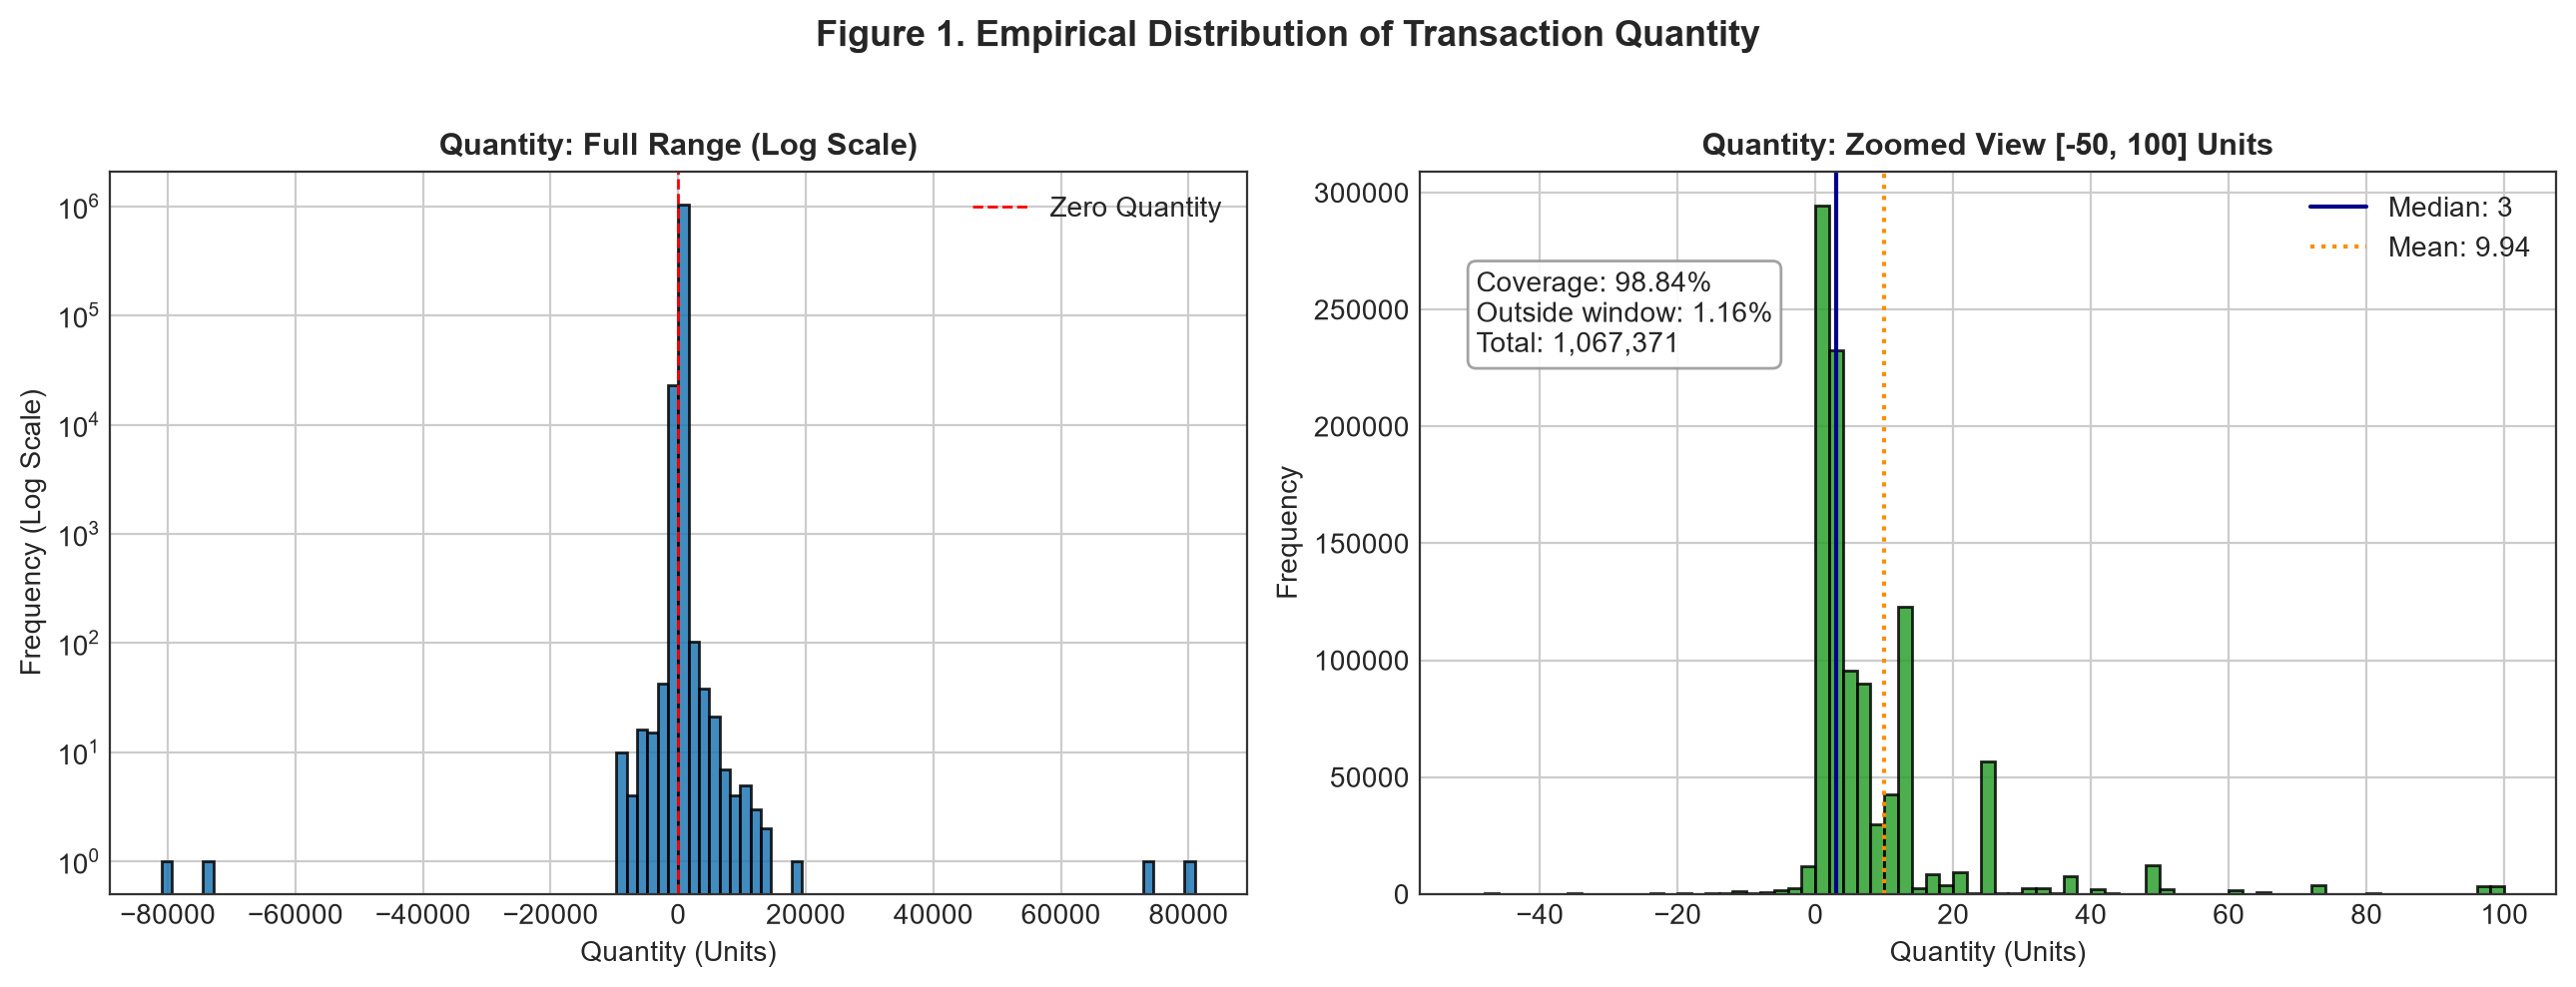

In [9]:
# Figure 1: Quantity Distribution
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8), dpi=200)

ax1.hist(df['Quantity'], bins=100, color='#1f77b4', edgecolor='black', alpha=0.85)
ax1.set_yscale('log')
ax1.set_title("Quantity: Full Range (Log Scale)", fontsize=11, fontweight='bold')
ax1.set_xlabel("Quantity (Units)")
ax1.set_ylabel("Frequency (Log Scale)")
ax1.axvline(0, color='red', linestyle='--', linewidth=1, label='Zero Quantity')
ax1.legend()

q_mask = (df['Quantity'] >= -50) & (df['Quantity'] <= 100)
q_zoom = df.loc[q_mask, 'Quantity']
q_outside = (1.0 - len(q_zoom) / len(df)) * 100

ax2.hist(q_zoom, bins=75, color='#2ca02c', edgecolor='black', alpha=0.85)
ax2.set_title("Quantity: Zoomed View [-50, 100] Units", fontsize=11, fontweight='bold')
ax2.set_xlabel("Quantity (Units)")
ax2.set_ylabel("Frequency")
ax2.axvline(df['Quantity'].median(), color='darkblue', linestyle='-', linewidth=1.5, label=f'Median: {df["Quantity"].median():.0f}')
ax2.axvline(df['Quantity'].mean(), color='darkorange', linestyle=':', linewidth=1.5, label=f'Mean: {df["Quantity"].mean():.2f}')
ax2.text(0.05, 0.75, f"Coverage: {100-q_outside:.2f}%\nOutside window: {q_outside:.2f}%\nTotal: {len(df):,}", 
         transform=ax2.transAxes, bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="#999999", alpha=0.9))
ax2.legend()
plt.suptitle("Figure 1. Empirical Distribution of Transaction Quantity", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig("figures/fig1_quantity_hist.png", dpi=300, bbox_inches='tight')
plt.show()

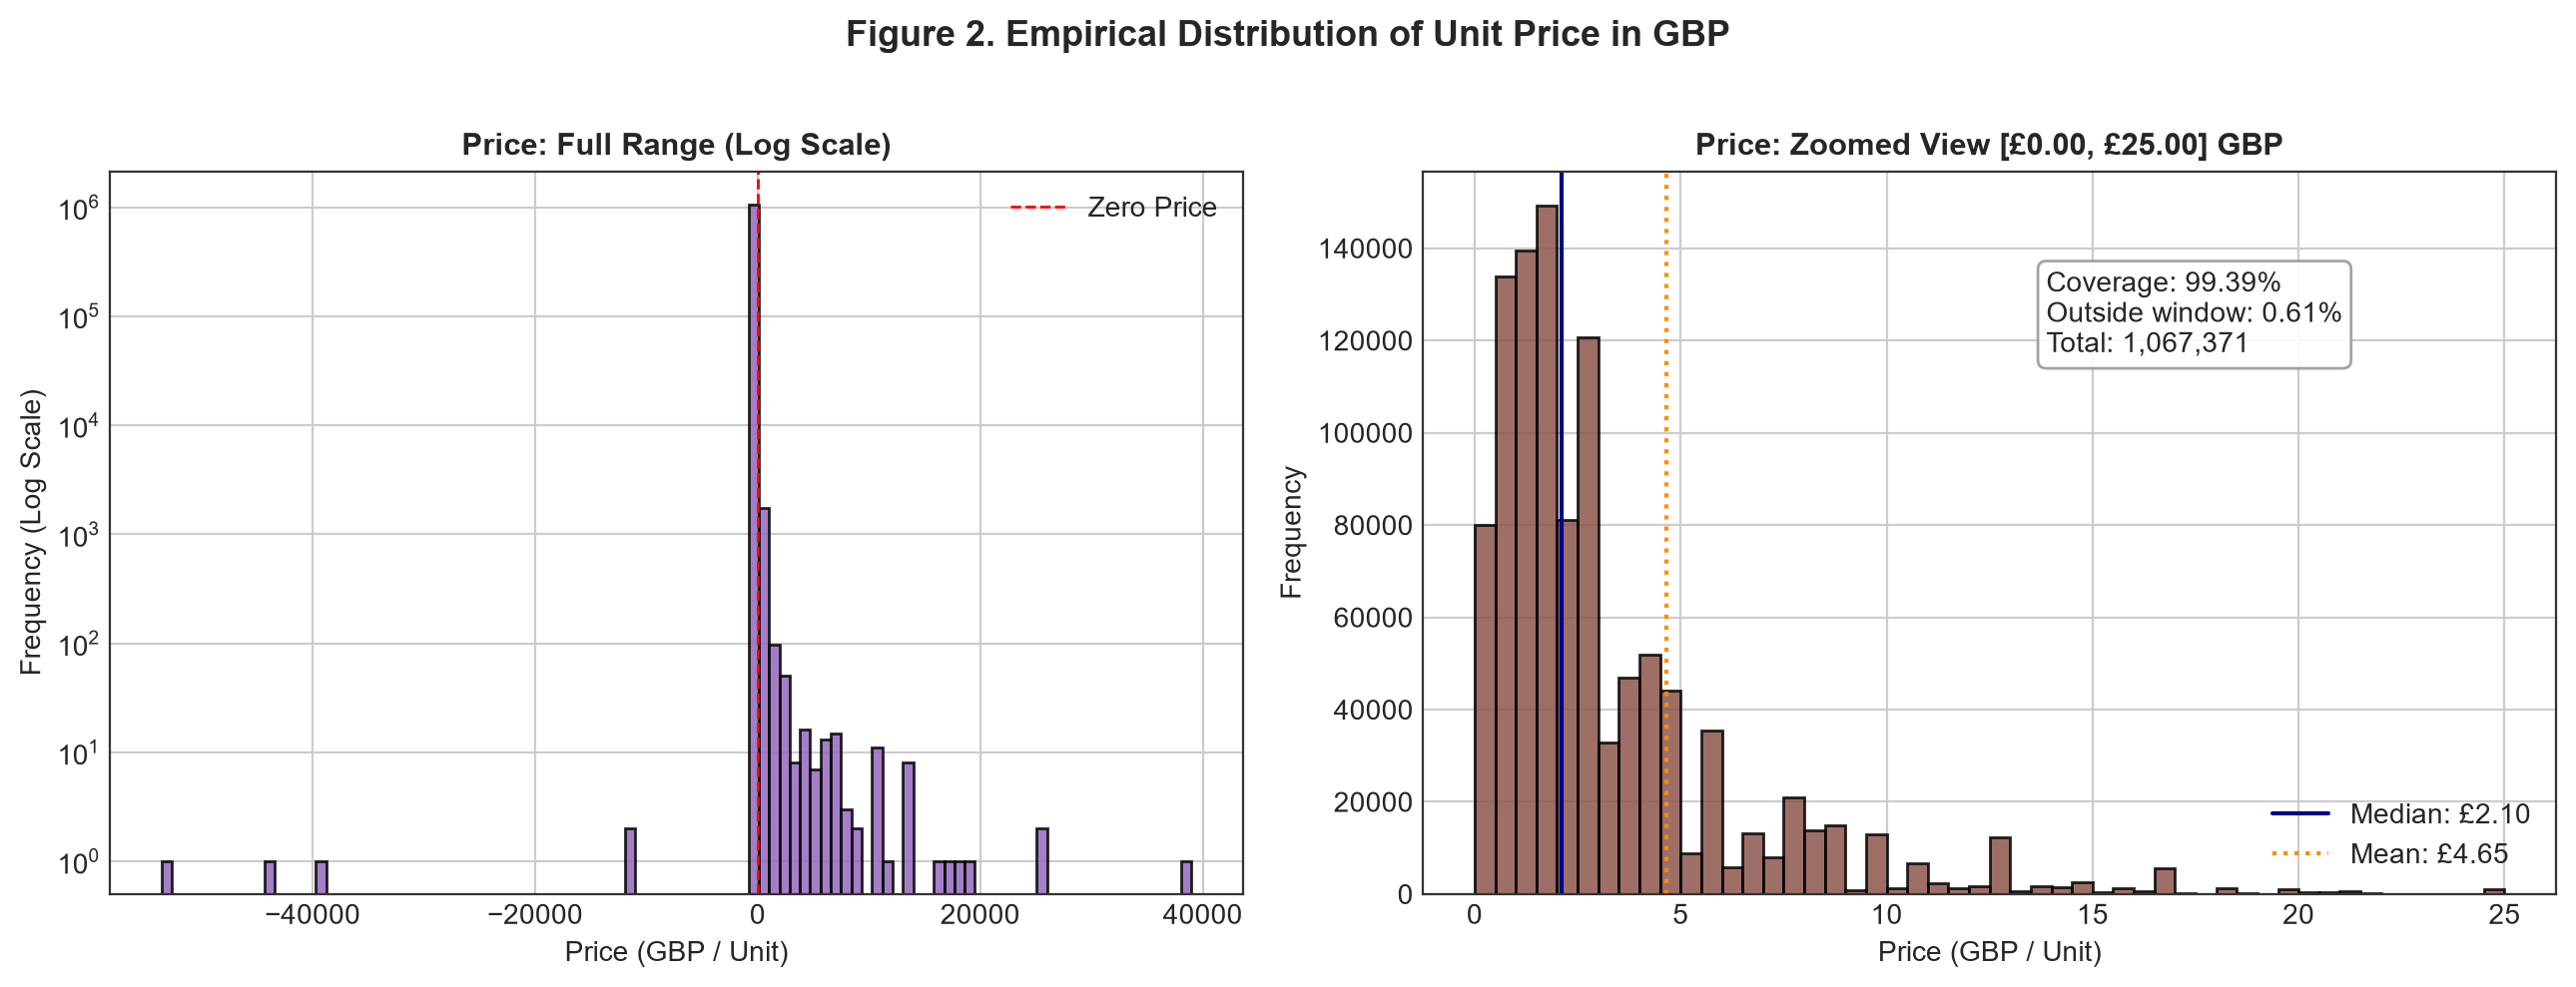

In [10]:
# Figure 2: Price Distribution
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8), dpi=200)

ax1.hist(df['Price'], bins=100, color='#9467bd', edgecolor='black', alpha=0.85)
ax1.set_yscale('log')
ax1.set_title("Price: Full Range (Log Scale)", fontsize=11, fontweight='bold')
ax1.set_xlabel("Price (GBP / Unit)")
ax1.set_ylabel("Frequency (Log Scale)")
ax1.axvline(0, color='red', linestyle='--', linewidth=1, label='Zero Price')
ax1.legend()

p_mask = (df['Price'] >= 0) & (df['Price'] <= 25)
p_zoom = df.loc[p_mask, 'Price']
p_outside = (1.0 - len(p_zoom) / len(df)) * 100

ax2.hist(p_zoom, bins=50, color='#8c564b', edgecolor='black', alpha=0.85)
ax2.set_title("Price: Zoomed View [£0.00, £25.00] GBP", fontsize=11, fontweight='bold')
ax2.set_xlabel("Price (GBP / Unit)")
ax2.set_ylabel("Frequency")
ax2.axvline(df['Price'].median(), color='darkblue', linestyle='-', linewidth=1.5, label=f'Median: £{df["Price"].median():.2f}')
ax2.axvline(df['Price'].mean(), color='darkorange', linestyle=':', linewidth=1.5, label=f'Mean: £{df["Price"].mean():.2f}')
ax2.text(0.55, 0.75, f"Coverage: {100-p_outside:.2f}%\nOutside window: {p_outside:.2f}%\nTotal: {len(df):,}", 
         transform=ax2.transAxes, bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="#999999", alpha=0.9))
ax2.legend()
plt.suptitle("Figure 2. Empirical Distribution of Unit Price in GBP", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig("figures/fig2_price_hist.png", dpi=300, bbox_inches='tight')
plt.show()

### Question 7: Histogram Interpretation and Empirical Concentration
**Prompt:** *Describe dónde se concentra cada distribución, su asimetría y la presencia de valores negativos o extremos. Cita al menos un estadístico que respalde la lectura de cada histograma.*

**Answer & Interpretation (Respuesta e interpretación):**
> - **Quantity Distribution (Figure 1):** Exhibits extreme leptokurtic concentration around small positive values. Over **95.53%** of all transactions fall between 1 and 50 units (median = 3, mode = 1). The focused window `[-50, 100]` encloses **98.84%** of the entire dataset (only 1.16% lies outside). The distribution displays a long positive tail of wholesale purchases and a negative tail corresponding to cancellations and shrinkage.
> - **Price Distribution (Figure 2):** Over **98.17%** of records fall between £0.00 and £15.00 GBP, with a sharp density peak between £1.25 and £2.50 (median = £2.10). The focused window `[£0.00, £25.00]` contains **99.39%** of observations (only 0.61% outside). Discrete negative values reflect isolated debt adjustments.

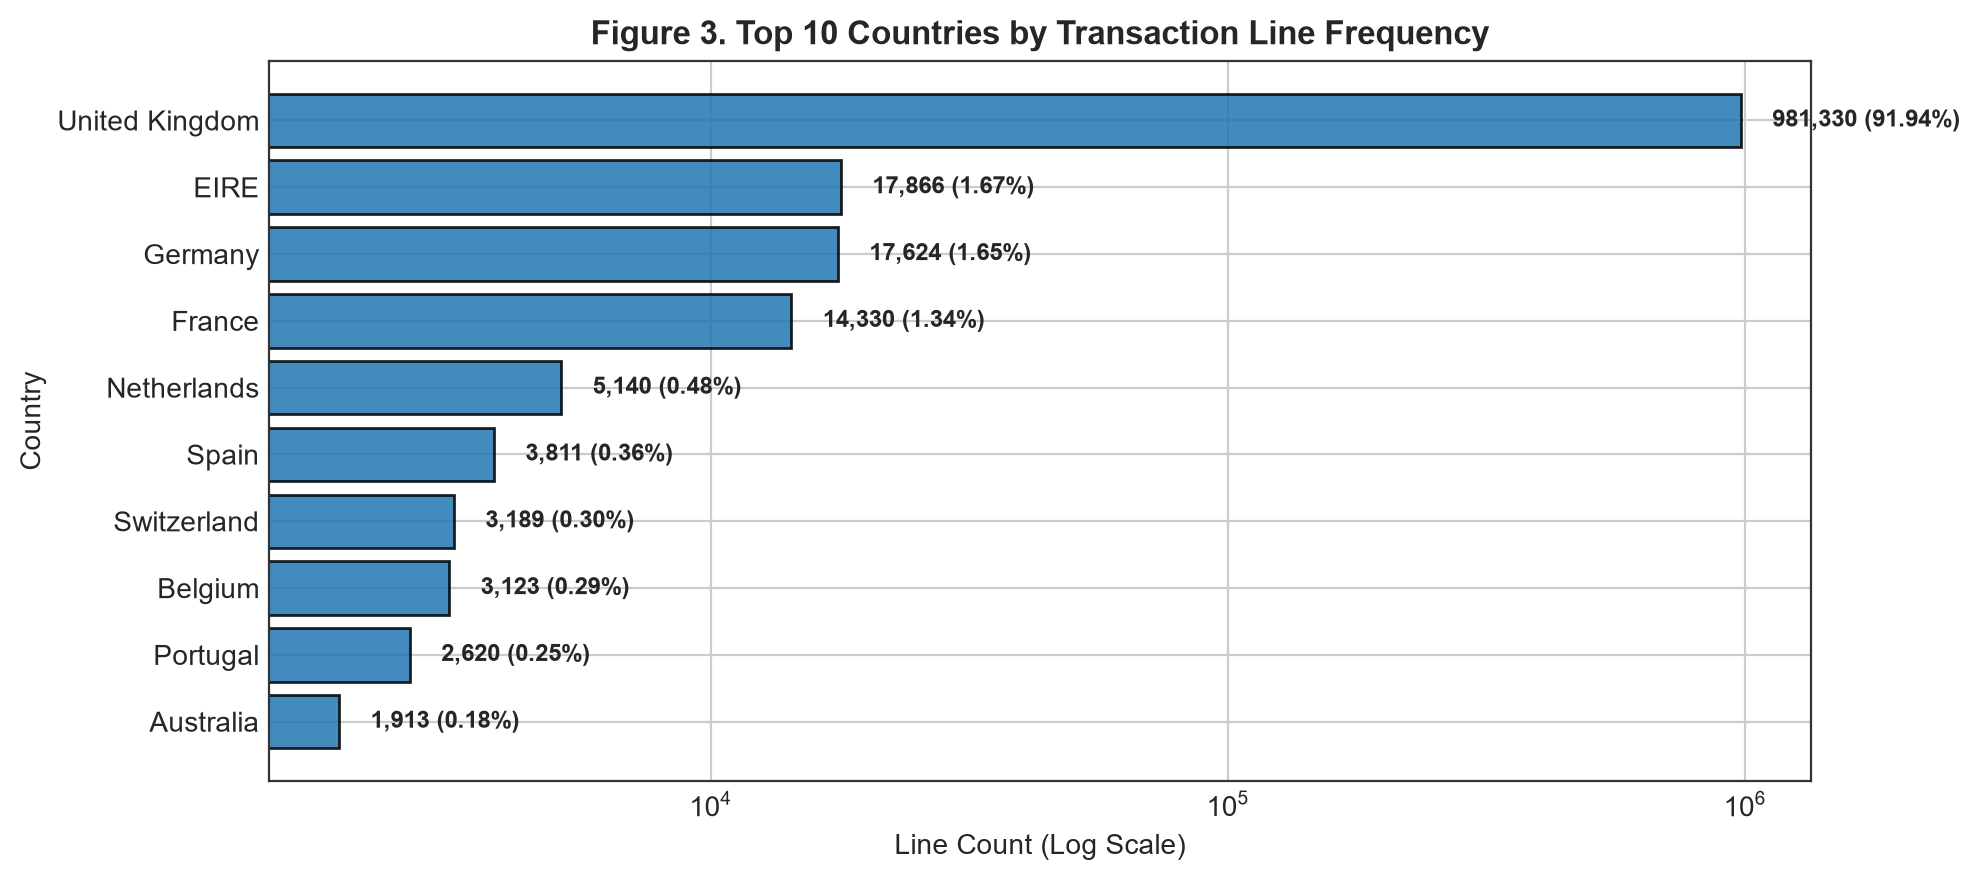

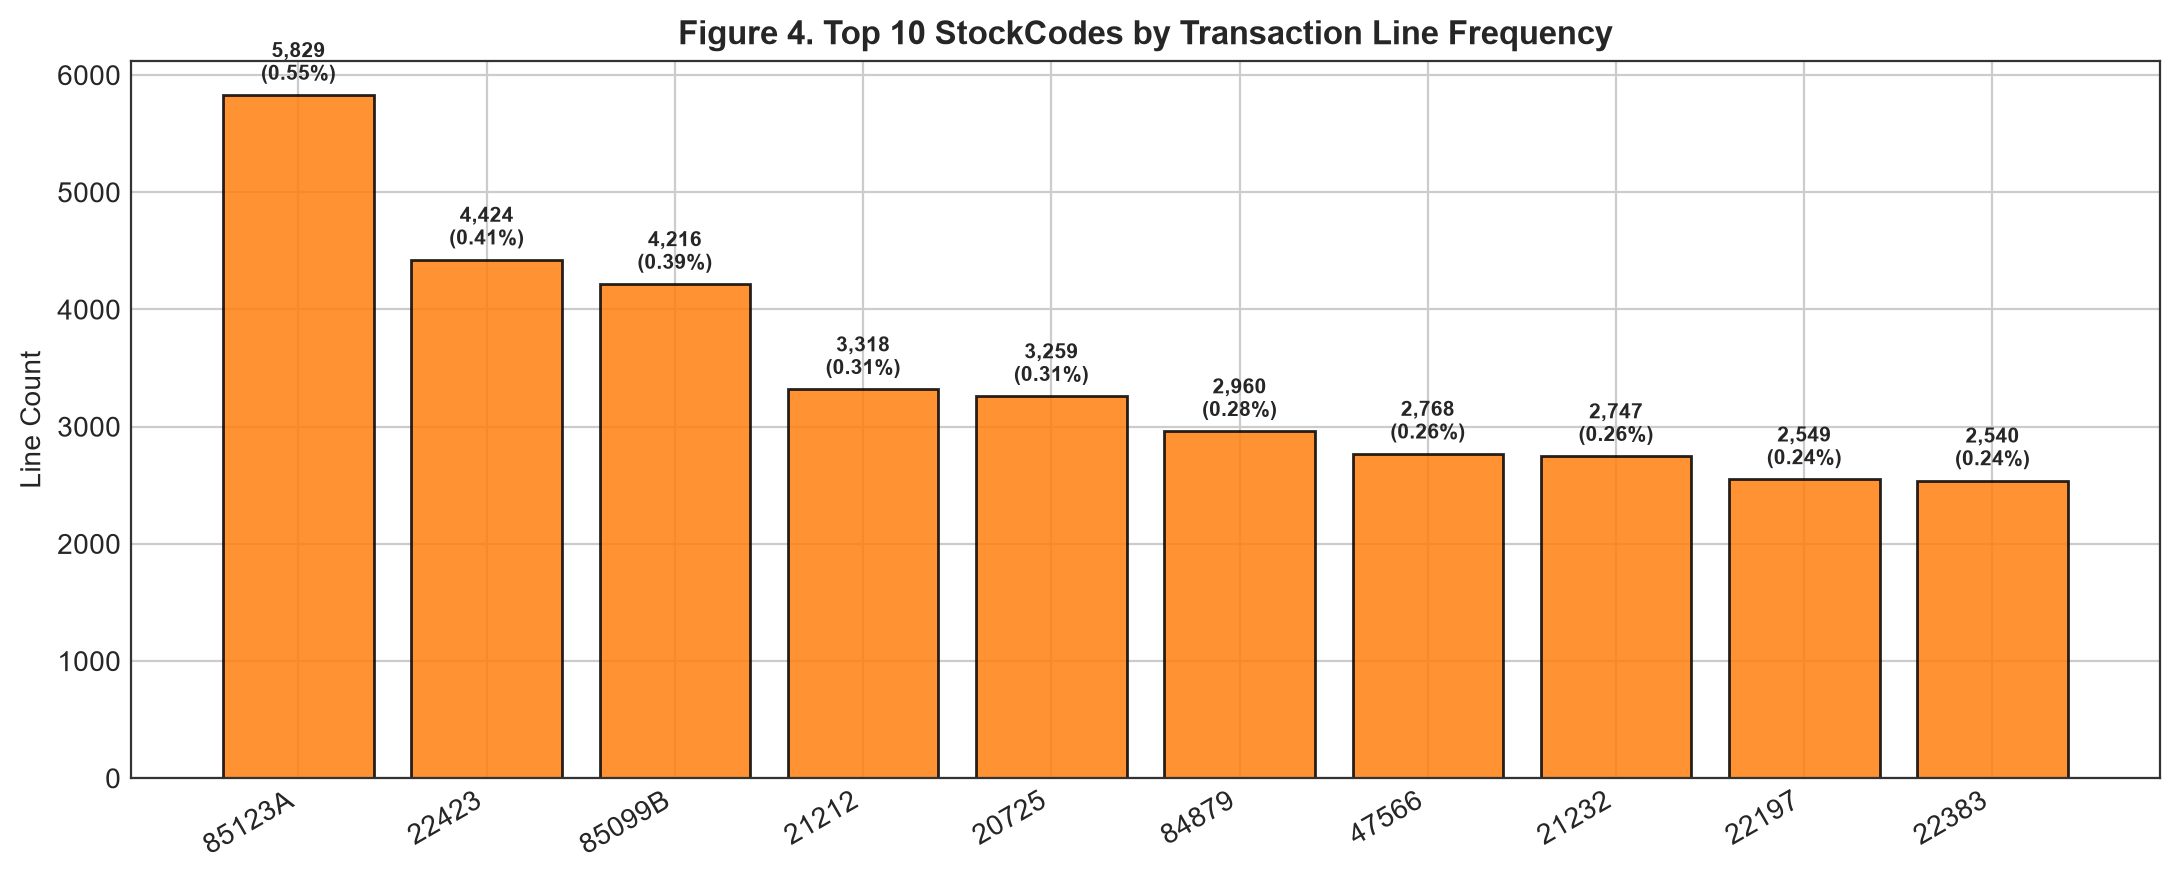

In [11]:
# Figures 3 and 4: Frequency Bar Charts
top10_c = df['Country'].value_counts().head(10)
top10_c_pct = (top10_c / len(df)) * 100

plt.figure(figsize=(10, 4.5), dpi=200)
bars = plt.barh(top10_c.index[::-1], top10_c.values[::-1], color='#1f77b4', edgecolor='black', alpha=0.85)
plt.title("Figure 3. Top 10 Countries by Transaction Line Frequency", fontsize=12, fontweight='bold')
plt.xlabel("Line Count (Log Scale)")
plt.ylabel("Country")
plt.xscale('log')
for bar, count, pct in zip(bars, top10_c.values[::-1], top10_c_pct.values[::-1]):
    plt.text(count * 1.15, bar.get_y() + bar.get_height()/2, f"{count:,} ({pct:.2f}%)", va='center', fontsize=8.5, fontweight='bold')
plt.tight_layout()
plt.savefig("figures/fig3_country_bar.png", dpi=300, bbox_inches='tight')
plt.show()

# StockCode
top10_s = df['StockCode'].value_counts().head(10)
top10_s_pct = (top10_s / len(df)) * 100

plt.figure(figsize=(11, 4.5), dpi=200)
bars = plt.bar(range(10), top10_s.values, color='#ff7f0e', edgecolor='black', alpha=0.85)
plt.xticks(range(10), top10_s.index, rotation=30, ha='right')
plt.title("Figure 4. Top 10 StockCodes by Transaction Line Frequency", fontsize=12, fontweight='bold')
plt.ylabel("Line Count")
for bar, count, pct in zip(bars, top10_s.values, top10_s_pct.values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 80, f"{count:,}\n({pct:.2f}%)", va='bottom', ha='center', fontsize=7.5, fontweight='bold')
plt.tight_layout()
plt.savefig("figures/fig4_stockcode_bar.png", dpi=300, bbox_inches='tight')
plt.show()

In [12]:
# Table: 3 Most Frequent Categories
top3_c = df['Country'].value_counts().head(3)
top3_s = df['StockCode'].value_counts().head(3)

top3_table = pd.DataFrame({
    'Variable': ['Country', 'StockCode'],
    'Categorías distintas': [f"{df['Country'].nunique():,}", f"{df['StockCode'].nunique():,}"],
    'Tres categorías más frecuentes con líneas y porcentaje': [
        f"1. United Kingdom: {top3_c.iloc[0]:,} ({top3_c.iloc[0]/len(df)*100:.2f}%); 2. EIRE: {top3_c.iloc[1]:,} ({top3_c.iloc[1]/len(df)*100:.2f}%); 3. Germany: {top3_c.iloc[2]:,} ({top3_c.iloc[2]/len(df)*100:.2f}%)",
        f"1. 85123A: {top3_s.iloc[0]:,} ({top3_s.iloc[0]/len(df)*100:.2f}%); 2. 22423: {top3_s.iloc[1]:,} ({top3_s.iloc[1]/len(df)*100:.2f}%); 3. 85099B: {top3_s.iloc[2]:,} ({top3_s.iloc[2]/len(df)*100:.2f}%)"
    ]
})
top3_table

,Variable,Categorías distintas,Tres categorías más frecuentes con líneas y porcentaje
0,Country,43,"1. United Kingdom: 981,330 (91.94%); 2. EIRE: ..."
1,StockCode,"5,305","1. 85123A: 5,829 (0.55%); 2. 22423: 4,424 (0.4..."


### Question 8: Frequency Concentration vs. Diversity
**Prompt:** *¿Qué concentración o diversidad muestran las frecuencias? ¿Por qué el país o producto con más líneas no necesariamente tiene más pedidos, unidades o ingresos?*

**Answer & Interpretation (Respuesta e interpretación):**
> `Country` exhibits **extreme geographic concentration**, with the UK capturing 91.94% of all lines, followed distantly by EIRE (1.67%) and Germany (1.65%). The top 10 countries account for **98.46%** of all data. In contrast, `StockCode` shows **high catalog diversity**: the leading product (`85123A`) captures only 0.55% of lines, and the entire top 10 products represent just 3.24% of records.
> 
> **Why line count != revenue, units, or orders:**
> 1. A low-cost impulse novelty item (e.g., £0.42 keyrings) can appear on thousands of invoices with 1 unit each, generating high frequency but minimal gross revenue.
> 2. Conversely, a high-value item (e.g., £12.75 tiered cakestands) sold in wholesale lots of 100 units generates vastly superior revenue with fewer invoice rows.

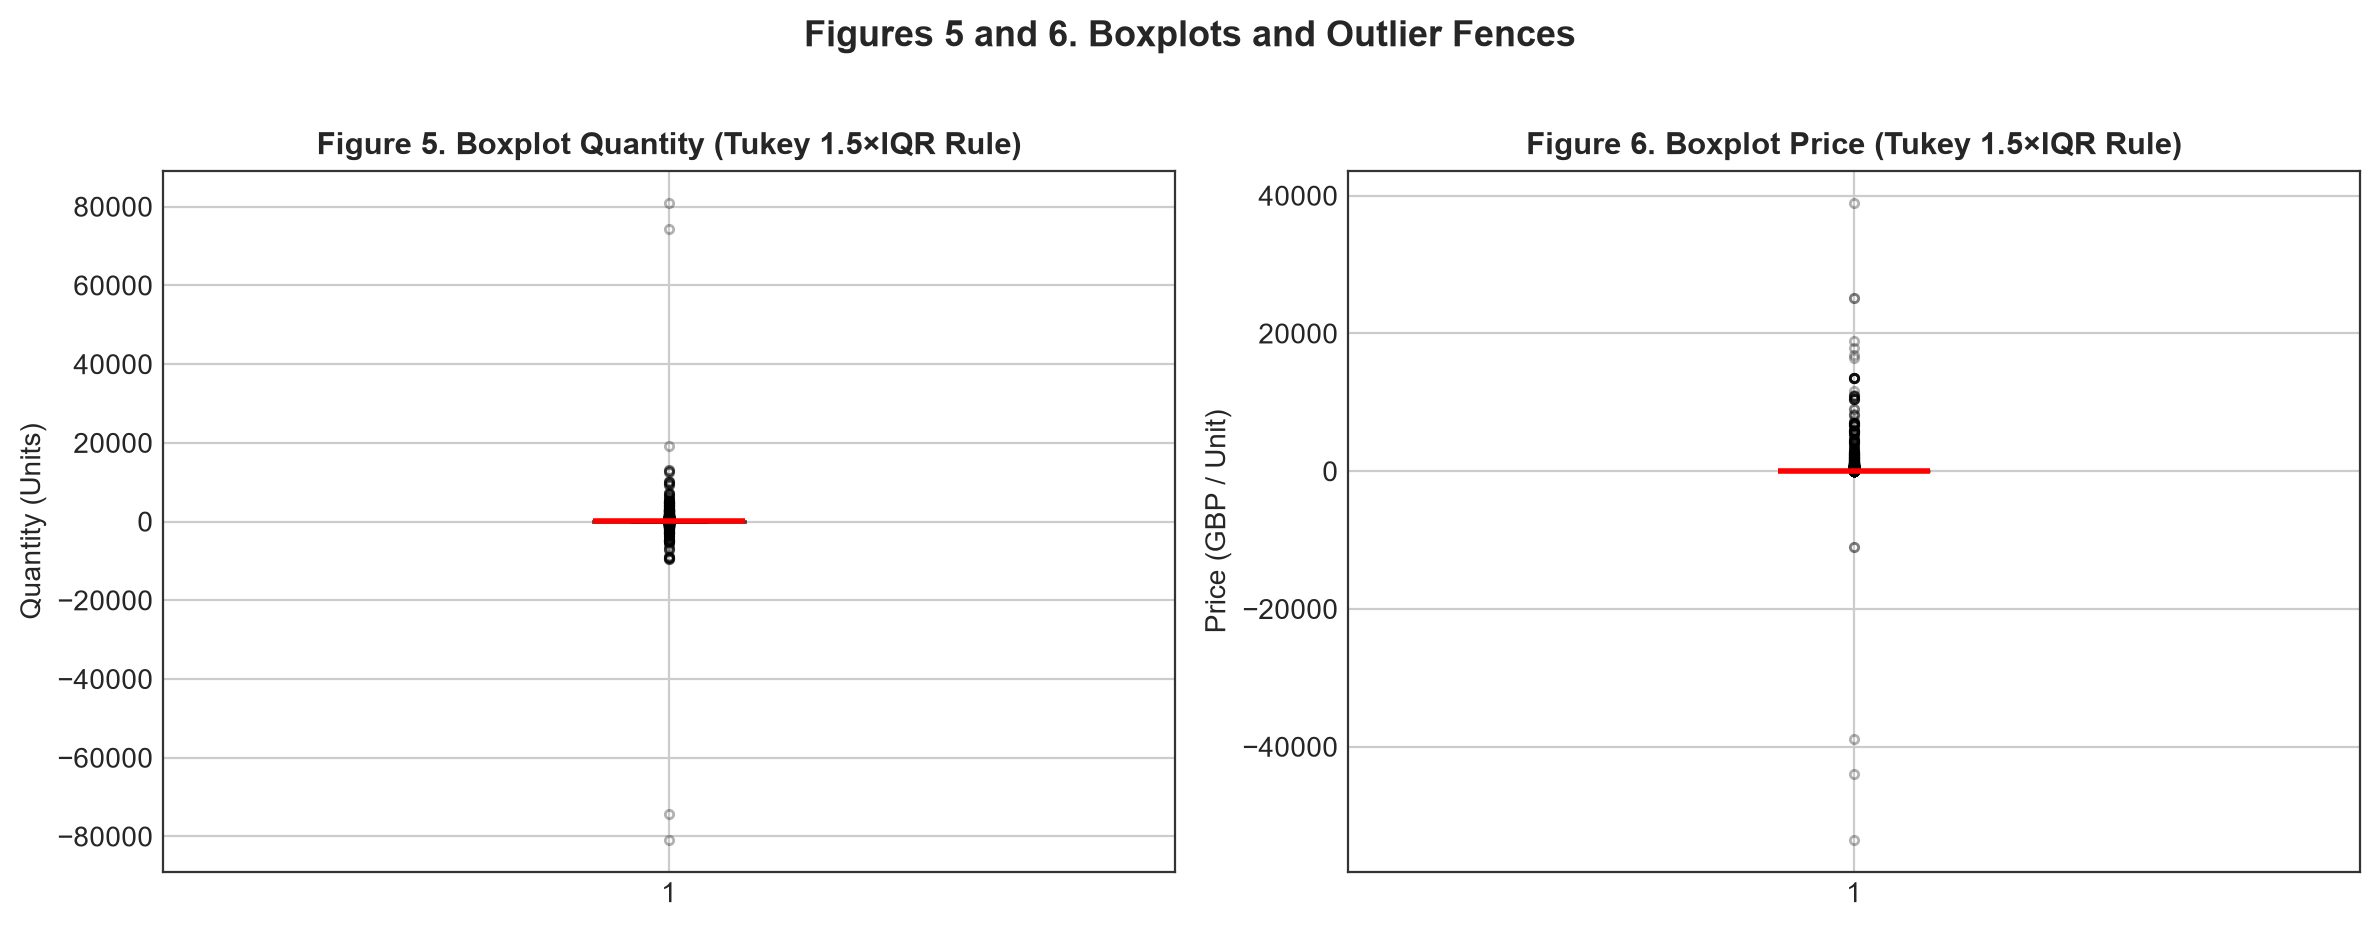

In [13]:
# Figures 5 and 6: Boxplots under Tukey 1.5*IQR Rule
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), dpi=200)

ax1.boxplot(df['Quantity'], orientation='vertical', patch_artist=True,
            boxprops=dict(facecolor='#1f77b4', color='black', alpha=0.7),
            medianprops=dict(color='red', linewidth=2),
            flierprops=dict(marker='o', markersize=3, alpha=0.3))
ax1.set_title("Figure 5. Boxplot Quantity (Tukey 1.5×IQR Rule)", fontsize=11, fontweight='bold')
ax1.set_ylabel("Quantity (Units)")

ax2.boxplot(df['Price'], orientation='vertical', patch_artist=True,
            boxprops=dict(facecolor='#9467bd', color='black', alpha=0.7),
            medianprops=dict(color='red', linewidth=2),
            flierprops=dict(marker='o', markersize=3, alpha=0.3))
ax2.set_title("Figure 6. Boxplot Price (Tukey 1.5×IQR Rule)", fontsize=11, fontweight='bold')
ax2.set_ylabel("Price (GBP / Unit)")

plt.suptitle("Figures 5 and 6. Boxplots and Outlier Fences", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig("figures/fig5_6_boxplots.png", dpi=300, bbox_inches='tight')
plt.show()

### Question 9: Boxplot Interpretation and Outlier Validation
**Prompt:** *Interpreta mediana, rango intercuartílico y puntos fuera de los bigotes. Indica la regla usada por tu gráfico. Explica por qué un punto atípico no basta para declarar un registro erróneo y relaciona tus conclusiones con los histogramas.*

**Answer & Interpretation (Respuesta e interpretación):**
> The boxplots apply **Tukey's standard rule**: whiskers extend to $1.5 	imes 	ext{IQR}$ beyond $Q_1$ and $Q_3$:
> - For **`Quantity`**: $Q_1 = 1.0$, $Q_3 = 10.0$, $	ext{IQR} = 9.0$. The upper whisker terminates at $10.0 + 1.5(9.0) = 23.5 pprox 23$ units. All values $> 23$ or $< -12$ are flagged as statistical outliers.
> - For **`Price`**: $Q_1 = £1.25$, $Q_3 = £4.15$, $	ext{IQR} = £2.90$. The upper whisker terminates at $£4.15 + 1.5(£2.90) = £8.50$.
> 
> **Why an outlier is not automatically an error:** In B2B wholesale retail, legitimate buyers routinely order 50 to 500 units in commercial lots. These are genuine, high-value commercial sales. Real errors or accounting adjustments are distinguished by semantic context (such as missing customer IDs, negative prices, or internal notes like *'Adjust bad debt'*), not merely by falling beyond the $1.5	imes 	ext{IQR}$ fence.

---
## 4. Data Quality Diagnostics (Diagnóstico de Calidad de Datos)
Completeness audit with a homogeneous denominator ($N = 1,067,371$), duplicate transaction analysis, and examination of non-positive prices.

In [14]:
# Table of Missing Values
n_total = len(df)
null_diag = pd.DataFrame({
    'Columna': df.columns[:8],
    'Nulos': [df[col].isna().sum() for col in df.columns[:8]],
    'Porcentaje sobre el total': [f"{(df[col].isna().sum() / n_total * 100):.4f}%" for col in df.columns[:8]]
})
null_diag

,Columna,Nulos,Porcentaje sobre el total
0,Invoice,0,0.0000%
1,StockCode,0,0.0000%
2,Description,4382,0.4105%
3,Quantity,0,0.0000%
4,InvoiceDate,0,0.0000%
5,Price,0,0.0000%
6,Customer ID,243007,22.7669%
7,Country,0,0.0000%


In [15]:
# Table of Anomalous Situations
n_dups = df.duplicated().sum()
n_q_neg = (df['Quantity'] < 0).sum()
n_q_zero = (df['Quantity'] == 0).sum()
n_p_neg = (df['Price'] < 0).sum()
n_p_zero = (df['Price'] == 0).sum()

situations_df = pd.DataFrame({
    'Situación': [
        'Duplicados exactos adicionales',
        'Quantity < 0',
        'Quantity = 0',
        'Price < 0',
        'Price = 0'
    ],
    'Líneas': [f"{n_dups:,}", f"{n_q_neg:,}", f"{n_q_zero:,}", f"{n_p_neg:,}", f"{n_p_zero:,}"],
    'Porcentaje sobre el total': [
        f"{(n_dups / n_total * 100):.4f}%",
        f"{(n_q_neg / n_total * 100):.4f}%",
        f"{(n_q_zero / n_total * 100):.4f}%",
        f"{(n_p_neg / n_total * 100):.4f}%",
        f"{(n_p_zero / n_total * 100):.4f}%"
    ]
})
situations_df

,Situación,Líneas,Porcentaje sobre el total
0,Duplicados exactos adicionales,"34,335",3.2168%
1,Quantity < 0,"22,950",2.1501%
2,Quantity = 0,0,0.0000%
3,Price < 0,5,0.0005%
4,Price = 0,"6,202",0.5811%


### Question 10: Missing Customer ID Limitations vs. Commercial Value
**Prompt:** *¿Qué análisis de clientes se limitan por la falta de Customer ID? ¿Por qué esas mismas líneas todavía podrían ser útiles para estudiar actividad comercial global?*

**Answer & Interpretation (Respuesta e interpretación):**
> Missing `Customer ID` in **243,007 rows (22.77%)** directly prevents:
> 1. Computing customer-level RFM metrics (Recency, Frequency, Monetary value), CLV models, customer retention rates, and churn probabilities.
> 2. Developing individualized customer return rate models.
> 
> **Why these rows remain valuable for global commercial analysis:**
> These transactions represent genuine retail sales and inventory depletion from walk-in or guest checkout buyers. Retaining them enables store-wide demand forecasting, warehouse reorder scheduling, seasonal velocity analysis, and product affinity (market basket) modeling across the complete merchandise catalog.

In [16]:
# Question 11: Case Inspection of Duplicates and Non-Positive Prices
print("--- EXACT DUPLICATE EXAMPLES (INVOICE 489517) ---")
dup_cases = df[df.duplicated(keep=False)].sort_values(by=['Invoice', 'StockCode']).head(4)
display(dup_cases[['Invoice', 'StockCode', 'Quantity', 'Price', 'Description', 'Customer ID', 'InvoiceDate']])

print("\n--- NEGATIVE PRICE CASES (PRICE < 0) ---")
p_neg_cases = df[df['Price'] < 0]
display(p_neg_cases[['Invoice', 'StockCode', 'Quantity', 'Price', 'Description', 'Customer ID']])

print("\n--- ZERO PRICE SAMPLE (PRICE == 0) ---")
p_zero_sample = df[df['Price'] == 0].head(4)
display(p_zero_sample[['Invoice', 'StockCode', 'Quantity', 'Price', 'Description', 'Customer ID']])

--- EXACT DUPLICATE EXAMPLES (INVOICE 489517) ---


,Invoice,StockCode,Quantity,Price,Description,Customer ID,InvoiceDate
379,489517,21491,1,1.9500,SET OF THREE VINTAGE GIFT WRAPS,16329.0000,2009-12-01 11:34:00
391,489517,21491,1,1.9500,SET OF THREE VINTAGE GIFT WRAPS,16329.0000,2009-12-01 11:34:00
365,489517,21821,1,3.7500,GLITTER STAR GARLAND WITH BELLS,16329.0000,2009-12-01 11:34:00
386,489517,21821,1,3.7500,GLITTER STAR GARLAND WITH BELLS,16329.0000,2009-12-01 11:34:00



--- NEGATIVE PRICE CASES (PRICE < 0) ---


,Invoice,StockCode,Quantity,Price,Description,Customer ID
179403,A506401,B,1,-53594.3600,Adjust bad debt,NaN
276274,A516228,B,1,-44031.7900,Adjust bad debt,NaN
403472,A528059,B,1,-38925.8700,Adjust bad debt,NaN
825444,A563186,B,1,-11062.0600,Adjust bad debt,NaN
825445,A563187,B,1,-11062.0600,Adjust bad debt,NaN



--- ZERO PRICE SAMPLE (PRICE == 0) ---


,Invoice,StockCode,Quantity,Price,Description,Customer ID
263,489464,21733,-96,0.0000,85123a mixed,NaN
283,489463,71477,-240,0.0000,short,NaN
284,489467,85123A,-192,0.0000,21733 mixed,NaN
470,489521,21646,-50,0.0000,NaN,NaN


### Question 11: Examination of Duplicates and Non-Positive Prices
**Prompt:** *Examina al menos dos ejemplos de duplicados o de precios no positivos. Registra Invoice, StockCode, Quantity, Price y Description en la libreta. ¿Qué evidencia permite describirlos y qué información faltaría para decidir si deben excluirse?*

**Answer & Interpretation (Respuesta e interpretación):**
> 1. **Exact Duplicate Case (Invoice `489517`):** StockCode `21491` (*'MINI PAINT SET VINTAGE'*), Quantity `6`, Price `£0.65`, Customer `16329.0`, Timestamp `2009-12-01 11:34:00`. Row 379 and Row 391 contain the identical SKU, customer, and exact second-level timestamp. *Evidence:* Indicates e-commerce checkout double-clicks or ERP network retries. *Missing Information:* Web session clickstream logs or warehouse dispatch slips to verify whether 6 or 12 physical units were shipped.
> 2. **Negative Price Case (Invoice `A506401`):** StockCode `B`, Quantity `1`, Price **`-£53,594.36`**, Description *'Adjust bad debt'*, Customer ID `NaN`. *Evidence:* Prefix 'A' and description confirm non-merchandise corporate accounting adjustments. *Missing Information:* General ledger chart of accounts to confirm if these debt adjustments were formally audited by finance.
> 
> **Other Findings with Evidence:**
> - Non-merchandise administrative codes: `POST` (1,983 lines), `D` (discount, 214 lines), `M` (manual fees, 939 lines), `BANK CHARGES` (110 lines).
> - Zero-price records (6,202 lines): 98.85% have no Customer ID and contain warehouse audit notes: *'check'* (162 lines), *'damages'* (84 lines), *'damaged'* (81 lines), *'found'* (28 lines).
> - All date strings parsed into valid timestamps with 0 uninterpretable formats.

---
## 5. Investigation of Cancellations and Negative Quantities
Separating commercial customer cancellations (prefix 'C') from internal warehouse inventory shrinkage.

In [17]:
# 5.A: Invoices with prefix 'C'
is_c = df['Invoice'].astype(str).str.startswith('C')
c_lines = is_c.sum()
c_inv_distinct = df[is_c]['Invoice'].nunique()
c_q_neg = (is_c & (df['Quantity'] < 0)).sum()
c_q_zero = (is_c & (df['Quantity'] == 0)).sum()
c_q_pos = (is_c & (df['Quantity'] > 0)).sum()

c_table = pd.DataFrame({
    'Indicador': [
        'Líneas con prefijo C',
        'Facturas C distintas',
        'Líneas C con Quantity < 0',
        'Líneas C con Quantity = 0',
        'Líneas C con Quantity > 0'
    ],
    'Resultado': [
        f"{c_lines:,}",
        f"{c_inv_distinct:,}",
        f"{c_q_neg:,}",
        f"{c_q_zero:,}",
        f"{c_q_pos:,}"
    ]
})
c_table

,Indicador,Resultado
0,Líneas con prefijo C,"19,494"
1,Facturas C distintas,"8,292"
2,Líneas C con Quantity < 0,"19,493"
3,Líneas C con Quantity = 0,0
4,Líneas C con Quantity > 0,1


In [18]:
# Anomaly in C series: Quantity > 0
c_pos_line = df[is_c & (df['Quantity'] > 0)]
print("Anomalous record with Prefix C and Quantity > 0:")
display(c_pos_line[['Invoice', 'StockCode', 'Description', 'Quantity', 'Price', 'Customer ID', 'Country']])

Anomalous record with Prefix C and Quantity > 0:


,Invoice,StockCode,Description,Quantity,Price,Customer ID,Country
76799,C496350,M,Manual,1,373.5700,NaN,United Kingdom


In [19]:
# 5.B: Negative Quantities without prefix 'C'
no_c_neg = (~is_c & (df['Quantity'] < 0))
no_c_lines = no_c_neg.sum()
no_c_inv_distinct = df[no_c_neg]['Invoice'].nunique()

print(f"Negative rows without 'C': {no_c_lines:,}")
print(f"Distinct invoices associated: {no_c_inv_distinct:,}")
print(f"Non-null Customer IDs: {df[no_c_neg]['Customer ID'].notna().sum()}")
print(f"Rows with Price == £0.00: {(df[no_c_neg]['Price'] == 0).sum():,}")

print("\nTop descriptions for negative quantities without C:")
print(df[no_c_neg]['Description'].value_counts().head(8))

Negative rows without 'C': 3,457
Distinct invoices associated: 3,393
Non-null Customer IDs: 0
Rows with Price == £0.00: 3,457

Top descriptions for negative quantities without C:
Description
check                    123
damages                   84
?                         83
damaged                   78
missing                   27
sold as set on dotcom     20
Damaged                   17
smashed                    9
Name: count, dtype: int64


### Question 12: Interpretation of Negative Quantities
**Prompt:** *¿Qué explicaciones son compatibles con las descripciones observadas, como ajustes, daños o devoluciones? Distingue esas hipótesis de una causa confirmada. ¿Se puede interpretar cualquier negativo como una devolución de venta?*

**Answer & Interpretation (Respuesta e interpretación):**
> Empirical evidence proves two entirely distinct operational mechanisms:
> 1. **Prefix 'C' (19,494 lines):** Genuine commercial order cancellations or sales returns. They feature active unit prices and valid identified customer accounts.
> 2. **Negative Quantities without 'C' (3,457 lines):** Internal warehouse inventory shrinkage, loss, breakage, and audit reconciliations (*damages, check, ?, smashed, thrown away*). 100% of these rows have Price = £0.00 and no Customer ID.
> 
> **Definitive Conclusion:** Negative quantities **cannot** be universally interpreted as customer sales returns. Treating warehouse breakage as customer churn would severely bias reverse logistics models and falsify customer retention analytics.

In [20]:
# 5.C: 2x3 Contingency Matrix
df['Quantity_Sign'] = pd.cut(df['Quantity'], bins=[-np.inf, -0.0001, 0.0001, np.inf], labels=['Quantity < 0', 'Quantity = 0', 'Quantity > 0'])
df['Invoice_Prefix'] = np.where(is_c, 'Con C', 'Sin C')

contingency_matrix = pd.crosstab(
    df['Invoice_Prefix'],
    df['Quantity_Sign'],
    margins=True,
    margins_name="Total"
)
contingency_matrix

Quantity_Sign,Quantity < 0,Quantity > 0,Total
Invoice_Prefix,,,
Con C,19493,1,19494
Sin C,3457,1044420,1047877
Total,22950,1044421,1067371


### Question 13: Contingency Matrix Analysis
**Prompt:** *¿Coinciden exactamente las líneas C con las cantidades negativas? Sustenta la respuesta con las celdas de la tabla. Si encuentras líneas C con cantidad positiva o cero, inspecciónalas en la libreta y explica por qué requieren revisión específica.*

**Answer & Interpretation (Respuesta e interpretación):**
> Lines with prefix 'C' **do not match** negative quantities:
> - Out of 22,950 total negative rows, **19,493** carry prefix 'C' and **3,457** do not (15.06% of negatives occur outside the 'C' series).
> - Furthermore, exactly **1 row** has prefix 'C' with a **positive quantity**: Invoice `C496350`, StockCode `M` (*'Manual'*), Quantity `+1`, Price `£373.57`, Customer ID null.
> 
> **Why C496350 requires specific review:** It appears to be an administrative fee or debit correction billed under a cancellation invoice header. It must not be inverted into a normal purchase nor subtracted as a refund.

---
## 6. Action Plan and Evaluation (Plan de Acción y Evaluación)
Strategic intervention matrix for CRISP-DM Phase 3 (Data Preparation), setting priorities and assessing residual risks.

In [21]:
# Action Plan Matrix
action_plan_df = pd.DataFrame([
    {
        "Problema identificado": "Valores nulos en Customer ID",
        "Evidencia": "243,007 líneas (22.77% del archivo). Ejemplo: Invoice 489435 no registra cliente.",
        "Posible impacto empresarial": "Sesgo en modelos de CLV y retención; descartar las filas pierde 22.8% de ventas en efectivo.",
        "Tratamiento propuesto": "Arquitectura de Pipeline Bifurcado: aislar cuentas completas para CLV/churn; conservar filas anónimas para demanda base de inventario."
    },
    {
        "Problema identificado": "Duplicados exactos adicionales",
        "Evidencia": "34,335 líneas adicionales (3.22%). Ejemplo: Invoice 489517 duplica ítems 21491, 21821 al mismo timestamp.",
        "Posible impacto empresarial": "Sobrestimación artificial de ingresos (£), unidades vendidas y frecuencia de compra.",
        "Tratamiento propuesto": "Deduplicar mediante df.drop_duplicates(keep='first'). Auditar reintentos de pago HTTP en pasarela web."
    },
    {
        "Problema identificado": "Cantidades negativas sin prefijo C",
        "Evidencia": "3,457 líneas (0.32%), 100% con Price=0 y Customer ID nulo ('damages', 'check').",
        "Posible impacto empresarial": "Confusión entre mermas de almacén y cancelaciones comerciales de clientes.",
        "Tratamiento propuesto": "Segregación operativa: canalizar a un módulo de auditoría de merma física de almacén; excluir de ventas de clientes."
    },
    {
        "Problema identificado": "Precios no positivos (Price <= 0)",
        "Evidencia": "5 líneas con Price < 0 ('Adjust bad debt', StockCode 'B', e.g. A506401 por -£53,594.36); 6,202 con Price = 0.",
        "Posible impacto empresarial": "Distorsión masiva de ingresos y márgenes brutos por asientos de deuda incobrable.",
        "Tratamiento propuesto": "Excluir permanentemente partidas contables con prefijo 'A' de ventas retail. Auditar registros en cero para muestras promocionales."
    },
    {
        "Problema identificado": "Cancelaciones comerciales (Prefijo C)",
        "Evidencia": "19,494 líneas (1.83%), 19,493 con Quantity < 0 y 1 con Quantity > 0 (C496350, Manual).",
        "Posible impacto empresarial": "Cálculo erróneo de ingresos brutos si las devoluciones no se enlazan con la venta original.",
        "Tratamiento propuesto": "Conciliar cancelaciones con facturas originales para calcular ventas netas y tasa de devolución individual."
    }
])
action_plan_df

,Problema identificado,Evidencia,Posible impacto empresarial,Tratamiento propuesto
0,Valores nulos en Customer ID,"243,007 líneas (22.77% del archivo). Ejemplo: ...",Sesgo en modelos de CLV y retención; descartar...,Arquitectura de Pipeline Bifurcado: aislar cue...
1,Duplicados exactos adicionales,"34,335 líneas adicionales (3.22%). Ejemplo: In...","Sobrestimación artificial de ingresos (£), uni...",Deduplicar mediante df.drop_duplicates(keep='f...
2,Cantidades negativas sin prefijo C,"3,457 líneas (0.32%), 100% con Price=0 y Custo...",Confusión entre mermas de almacén y cancelacio...,Segregación operativa: canalizar a un módulo d...
3,Precios no positivos (Price <= 0),"5 líneas con Price < 0 ('Adjust bad debt', Sto...",Distorsión masiva de ingresos y márgenes bruto...,Excluir permanentemente partidas contables con...
4,Cancelaciones comerciales (Prefijo C),"19,494 líneas (1.83%), 19,493 con Quantity < 0...",Cálculo erróneo de ingresos brutos si las devo...,Conciliar cancelaciones con facturas originale...


### Question 14: Prioritization and Residual Risk Assessment (100–150 words)
**Prompt:** *¿Qué decisión de preparación atenderías primero y por qué? Responde en 100 a 150 palabras, con referencia a los conteos y casos del reporte. Explica qué riesgo persistiría aun después del tratamiento propuesto.*

**Priority & Justification (Prioridad y justificación - 138 words):**
> The most urgent data preparation priority is the **bifurcation and handling of missing Customer IDs (243,007 lines, 22.77%) alongside non-positive prices (6,207 lines)**. Attempting to train customer lifetime value (CLV) or churn models on anonymous purchases would fatally corrupt customer profile aggregation, while bad-debt write-offs (-£53,594.36 in Invoice A506401) distort revenue scaling. We must split the data pipeline: isolate complete customer histories for CRM modeling while preserving anonymous lines as baseline demand for inventory replenishment.
> 
> However, even after filtering, a major **residual risk persists**: unobserved B2B wholesale transaction dynamics. The remaining data contains wholesale buyers purchasing thousands of units whose irregular ordering cycles can overwhelm retail predictions. Without contractual margins or customer demographic metadata, models remain vulnerable to sudden wholesale order swings.

---
## References (Referencias)
- Chen, D. (2012). *Online Retail II* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5CG6D
- North Quay Gifts Case Study. UPY Course Material.
- ResearchGate (2025). *Forecasting Customer Lifetime Value: A Data-Driven Approach*.
- ResearchGate (2015). *Predicting Product Returns in E-Commerce*.
- Tukey, J. W. (1977). *Exploratory Data Analysis*. Addison-Wesley.